In [2]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

In [3]:
from __future__ import division
import matplotlib.pyplot as plt
from deltasigma import *
import numpy as np
from IPython.core.display import Image
import numpy as np, pandas as pd

#from turtle import title
from matplotlib import text

In [4]:
from itertools import zip_longest as izip_longest

class Table(list):
    def _repr_html_(self):
        html = ["<table>"]
        for row in self:
            html.append("<tr>")
            for col in row:
                try:
                    float(col)
                    html.append("<td>%.6f</td>" % col)
                except(ValueError):
                    html.append("<td><b>%s</b></td>" % col)
            html.append("</tr>")
        html.append("</table>")
        return ''.join(html)

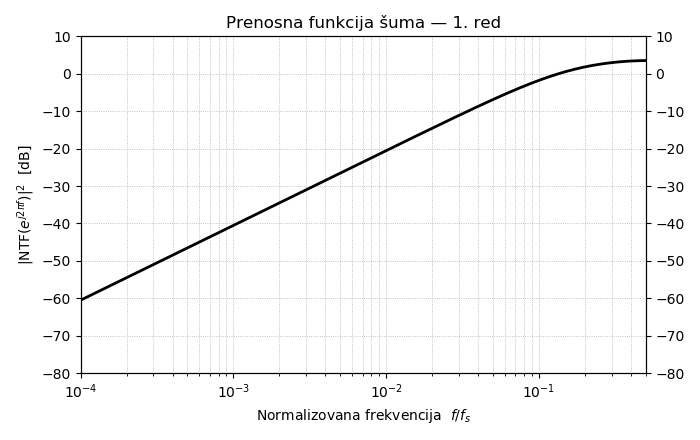

In [5]:
osr, Hinf = 1, 1.5
ntf = synthesizeNTF(1, osr, 1, Hinf)

f   = np.logspace(-4, np.log10(0.5), 2001)   # log osa ne moze da krene od 0
H   = evalTF(ntf, np.exp(2j*np.pi*f))
fB  = 0.5/osr
HdB = 20*np.log10(np.abs(H))

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.semilogx(f, HdB, 'k', lw=2, zorder=3)

ax.set_xlim(1e-4, 0.5)
ax.set_ylim(-80, 10)
ax.set_yticks(np.arange(-80, 11, 10))
ax.set_xlabel(r'Normalizovana frekvencija  $f/f_s$')
ax.set_ylabel(r'$|\mathrm{NTF}(e^{j2\pi f})|^2$  [dB]')
ax.set_title(r'Prenosna funkcija šuma — 1. red')
ax.grid(ls=':', lw=0.6, which='both', zorder=1)

axr = ax.twinx()
axr.set_ylim(ax.get_ylim()); axr.set_yticks(ax.get_yticks())
fig.tight_layout()

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_simulateDSM.py:214: UserWarning: Using a slow implementation of simulateDSM
Refer to the docs for how to switch to a fast one
  warn('Using a slow implementation of simulateDSM\n' +
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/ipykernel_launcher.py:21: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed in 3.0
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/

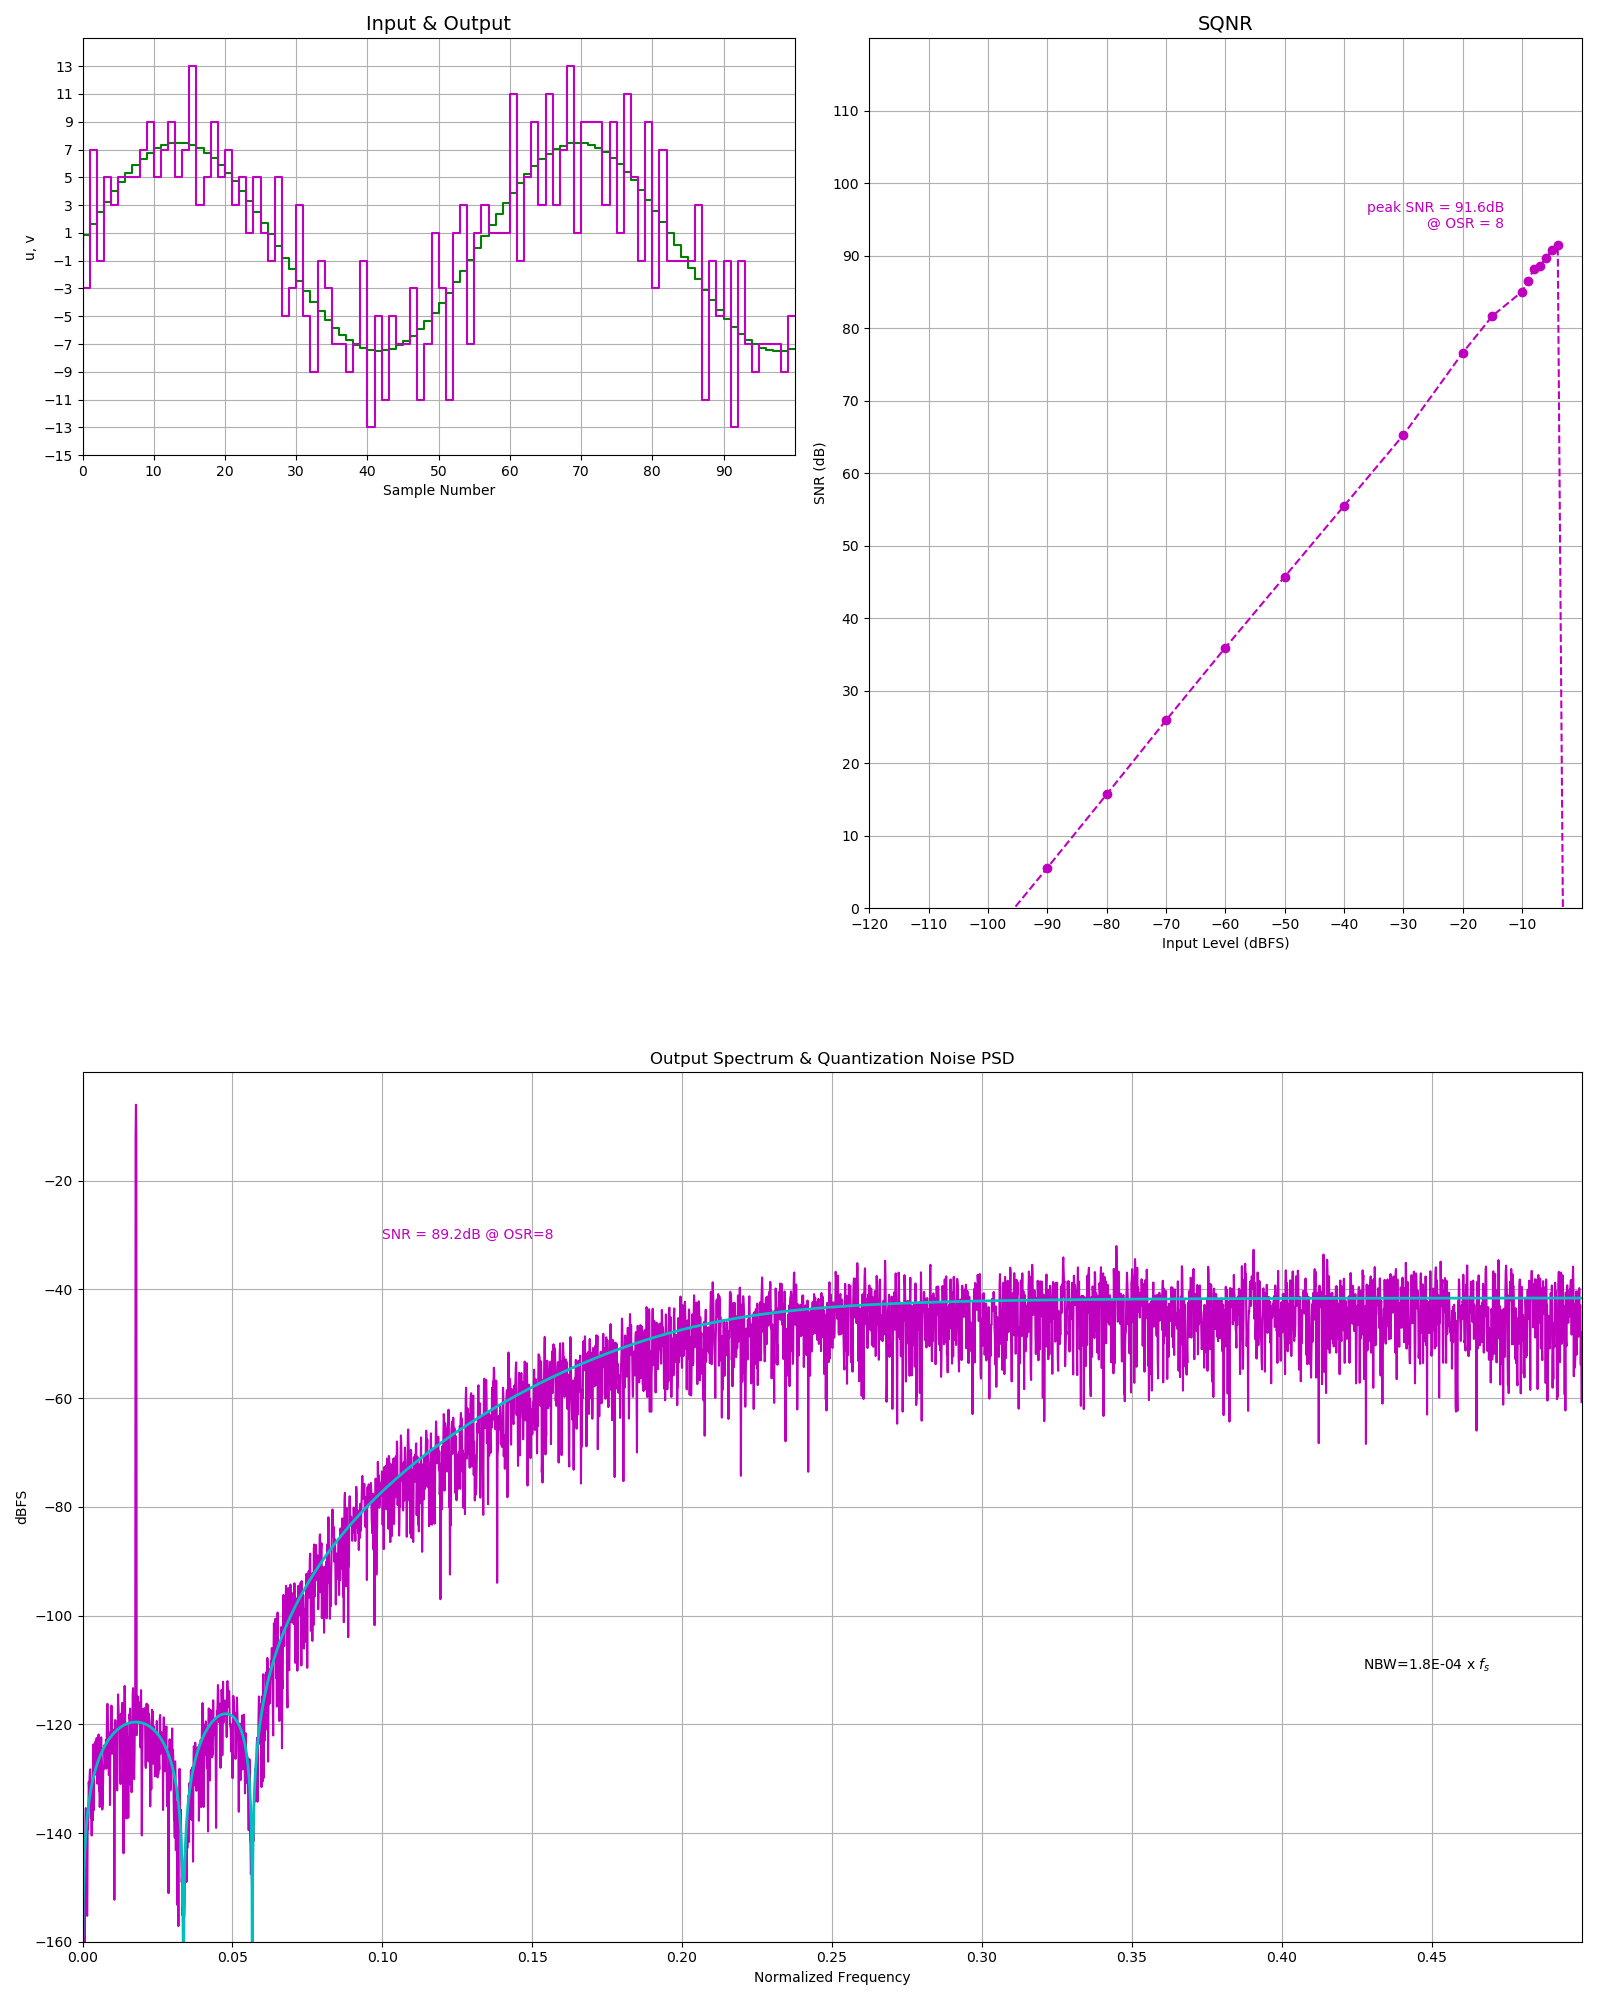

In [6]:
plt.figure(figsize=(16, 20))
colors = ('m')
Hinf_list = [8]
i = -1
order = 5
form = 'CRFBD'
for col, Hinf in zip(colors, Hinf_list):
    i += 2
    OSR = 8
    M = 15
    H = synthesizeNTF(order, OSR, 1, Hinf)
    N = 8192
    fB = int(np.ceil(N/(2.*OSR)))
    ftest = int(np.floor(2./7*fB))
    u = 0.5*M*np.sin(2*np.pi*ftest/N*np.arange(N))
    v, xn, xmax, y = simulateDSM(u, H, M + 1)
    
    plt.subplot(int('42' + str(i)))
    t = np.arange(101)
    plt.step(t, u[t], 'g')
    plt.hold(True)
    plt.step(t, v[t], col)
    figureMagic([0, 100], 10, None, [-M, M], 2, None, None,'Input & Output')
    plt.xlabel('Sample Number')
    plt.ylabel('u, v')
    
    plt.subplot(222)
    snr, amp = simulateSNR(H, OSR, None, 0., M + 1)
    plt.plot(amp, snr,'o' + col, amp, snr, '--' + col)
    plt.hold(True)
    figureMagic([-120, 0], 10, None, [0, 120], 10, None, None,'SQNR')
    plt.xlabel('Input Level (dBFS)')
    plt.ylabel('SNR (dB)')
    pk_snr, pk_amp = peakSNR(snr, amp)
    plt.text(-13, pk_snr, 'peak SNR = %4.1fdB\n@ OSR = %d\n' % (pk_snr, OSR), horizontalalignment='right', color=col)
    
    plt.subplot(212)
    f = np.linspace(0, 0.5, N//2 + 1)
    spec = np.fft.fft(v*ds_hann(N))/(M*N/4)
    plt.plot(f, dbv(spec[:N//2 + 1]), col)
    snr = calculateSNR(spec[2:fB + 1], ftest - 2)
    plt.text(0.1, 10*(i - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color=col)
    figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, None,'Output Spectrum')
    plt.xlabel('Normalized Frequency')
    plt.ylabel('dBFS')
    
    NBW = 1.5/N
    Sqq = 4*np.abs(evalTF(H, np.exp(2j*np.pi*f)))**2/(3.*M**2)
    plt.hold(True)
    plt.plot(f, dbp(Sqq*NBW), 'c', linewidth=2)
    if i == 1:
        plt.text(0.47, -110, 'NBW=%4.1E x $f_s$ '% NBW, horizontalalignment='right')
plt.title('Output Spectrum & Quantization Noise PSD')
plt.tight_layout()

In [7]:
print(pretty_lti(H))


      (z^2 - 1.875z + 0.9999) (z^2 - 1.955z + 1) (z - 1)      
--------------------------------------------------------------
 (z^2 - 0.377z + 0.3806) (z^2 - 0.552z + 0.1239) (z - 0.3007) 


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:85: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  hold_status = plt.ishold()
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_plotPZ.py:90: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
  plt.hold(True)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed

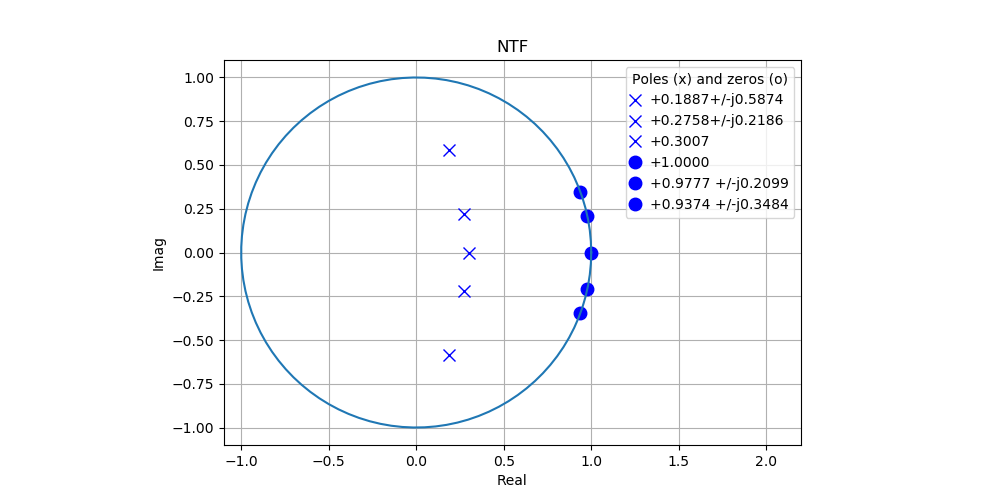

In [8]:
plt.figure(figsize=(10, 5))
plotPZ(H, showlist=True, markersize=9)
plt.title('NTF');

# Ovaj deo je a pravljenje abcd

In [7]:
a, g, b, c = realizeNTF(H, form=form)
b = np.concatenate((b[0].reshape((1,)), np.zeros((b.shape[0] - 1,))), axis=0)

t = Table()
ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']
t.append(['Coefficients', 'DAC feedback', 'Resonator feedback',
          'Feed-in', 'Interstage'])
t.append(['', 'a(n)', 'g(n)', ' b(n)', ' c(n)'])

for row in izip_longest(ilabels, a.tolist(), g.tolist(),
                       b.tolist(), c.tolist(), fillvalue=""):
    t.append(list(row))

t

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_realizeNTF.py:243: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  a = -np.real(np.linalg.lstsq(T.T, L1.T)[0]).T


Coefficients,DAC feedback,Resonator feedback,Feed-in,Interstage
,a(n),g(n),b(n),c(n)
#1,0.401436,0.044547,0.401436,1.000000
#2,1.314470,0.125303,0.000000,1.000000
#3,3.122564,,0.000000,1.000000
#4,2.614521,,0.000000,1.000000
#5,3.600342,,0.000000,1.000000
#6,,,0.000000,


# Ovaj deo je za trazenje maksime

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_stuffABCD.py:151: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  ABCD[subdiag] = c[0, dly]


The state maxima have been evaluated through simulation.


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/ipykernel_launcher.py:24: MatplotlibDeprecationWarning: pyplot.hold is deprecated.
    Future behavior will be consistent with the long-time default:
    plot commands add elements without first clearing the
    Axes and/or Figure.
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/__init__.py:913: MatplotlibDeprecationWarning: axes.hold is deprecated. Please remove it from your matplotlibrc and/or style files.
  mplDeprecation)
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/matplotlib/rcsetup.py:158: MatplotlibDeprecationWarning: axes.hold is deprecated, will be removed in 3.0
  mplDeprecation)


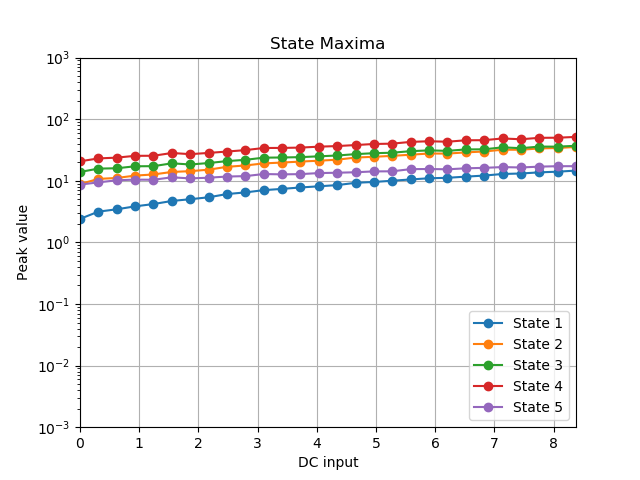

In [ ]:
ABCD = stuffABCD(a, g, b, c, form=form);
u = np.linspace(0, 0.6*M, 30);
N = 1e4; 
test_signal = np.ones((1, int(N)))
maxima = np.zeros((order, len(u)))
for i in range(len(u)):
    ui = u[i]
    v, xn, xmax, _ = simulateDSM(ui*test_signal, ABCD, M + 1);
    maxima[:, i] = np.squeeze(xmax)
    if any(xmax > 1e2):
        umax = ui;
        u = u[:i];
        maxima = maxima[:, :i]
        break;
# save the maxima
prescale_maxima = np.copy(maxima)
print('The state maxima have been evaluated through simulation.')

plt.figure()

for i in range(order):
    plt.semilogy(u, maxima[i, :], 'o-', label=('State %d' % (i+1)))
    if not i:
        plt.hold(True)
plt.grid(True)
plt.title('State Maxima'); plt.ylabel('Peak value'); plt.xlabel('DC input')
plt.xlim([0, u[-1]]); plt.ylim([1e-3, 1e3])
plt.legend(loc=4);

# Skalirana maksima

In [ ]:
ABCD = stuffABCD(a, g, b, c, form=form);

ABCDs, umax, S = scaleABCD(ABCD, nlev=nlev, N_sim=10000, xlim=0.9)

as_, gs, bs, cs = mapABCD(ABCDs, form=form)

print('umax =', umax)

print('Scaled modulator, umax = %.2f  (MSA iz SQNR ≈ %.2f)\n' % (umax, 0.63*nlev-1))
print('a =', np.round(as_.squeeze(), 4))
print('g =', np.round(gs.squeeze(), 4))
print('b =', np.round(bs.squeeze(), 4))
print('c =', np.round(cs.squeeze(), 4))

umax = 8.4
Scaled modulator, umax = 8.40  (MSA iz SQNR ≈ 9.08)

a = [0.0242 0.0327 0.0743 0.045  0.18  ]
g = [0.0466 0.0431]
b = [0.0242 0.     0.     0.     0.     0.    ]
c = [ 0.4116  0.9569  0.7231  2.9072 20.0005]


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_mapABCD.py:65: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  g = -ABCD[supdiag]


In [10]:
pk_snr, pk_amp = peakSNR(snr, amp)
print('pk_amp = %.2f dBFS  →  %.2f' % (pk_amp, (nlev-1)*10**(pk_amp/20)))
print('umax iz scaleABCD = %.2f' % umax)

pk_amp = nan dBFS  →  nan
umax iz scaleABCD = 8.40


/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_peakSNR.py:84: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  ab = np.linalg.lstsq(A, snr.reshape((-1, 1)))[0]
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_peakSNR.py:85: RuntimeWarning: invalid value encountered in sqrt
  peak_amp = c - np.sqrt(ab[1, 0]/ab[0, 0])


In [11]:
t = Table()
ilabels = ['#1', '#2', '#3', '#4', '#5', '#6']
t.append(['Coefficients', 'DAC feedback', 'Resonator feedback', 
          'Feed-in', 'Interstage'])
t.append(['', 'a(n)', 'g(n)', ' b(n)', ' c(n)'])
[t.append(x) for x in izip_longest(ilabels, as_.tolist(), gs.tolist(), bs.tolist(), cs.tolist(), fillvalue="")]
t

Coefficients,DAC feedback,Resonator feedback,Feed-in,Interstage
,a(n),g(n),b(n),c(n)
#1,0.024243,0.046552,0.024243,0.411569
#2,0.032671,0.043101,0.000000,0.956945
#3,0.074270,,0.000000,0.723081
#4,0.044966,,0.000000,2.907162
#5,0.180013,,0.000000,20.000489
#6,,,0.000000,


In [12]:
u = np.linspace(0, umax, 30)
N = 10000
T = np.ones((N,))
maxima = np.zeros((order, len(u)))
umax_sim = umax

for i in range(len(u)):
    ui = u[i]
    v, xn, xmax, _ = simulateDSM(ui*T, ABCDs, nlev)
    maxima[:, i] = xmax.squeeze()
    if np.any(xmax > 1e2):
        umax_sim = ui
        u = u[:i]
        maxima = maxima[:, :i]
        break

print('The state maxima have been re-evaluated through simulation.')
print('The maximum input was found to be %.6f' % umax_sim)
print('pre skaliranja:', prescale_maxima.max(axis=1))
print('posle:', maxima.max(axis=1))

The state maxima have been re-evaluated through simulation.
The maximum input was found to be 8.110345
pre skaliranja: [14.64548523 35.44275851 37.01985345 51.60711263 17.27390489]
posle: [0.86406032 0.87466286 0.88421907 0.87683268 0.88643955]


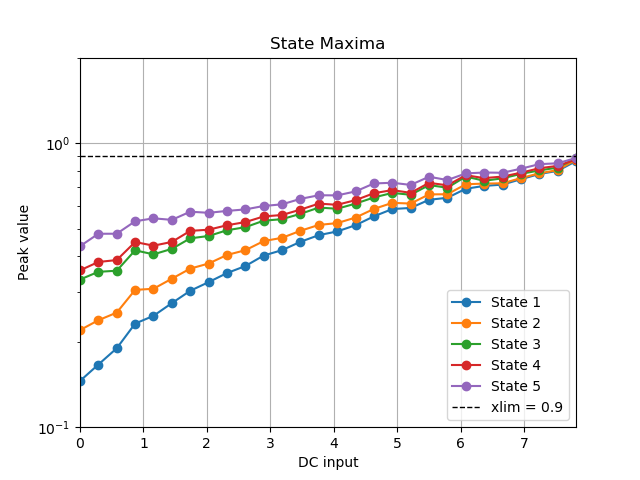

In [13]:
plt.figure()
for i in range(order):
    plt.semilogy(u, maxima[i, :], 'o-', label=('State %d' % (i+1)))
plt.grid(True)
plt.title('State Maxima')
plt.ylabel('Peak value')
plt.xlabel('DC input')
plt.xlim([0, u[-1]])
plt.ylim([1e-1, 2])
plt.axhline(0.9, color='k', ls='--', lw=1, label='xlim = 0.9')
plt.legend(loc=4)

In [ ]:
order = 5
OSR = 8
M = 15
form = 'CRFBD'
opt=1 
xlim = 0.9
nlev  = M + 1
N_sim = 10000

Hinf_list = [2.0, 3.0, 4.0, 8.0, 12.0]
rows = []

for Hinf in Hinf_list:
    r = {'Hinf': Hinf}

    H = synthesizeNTF(order, OSR, opt, Hinf)

    snr, amp = simulateSNR(H, OSR, None, 0., nlev)
    r['pkSQNR'], r['pkAmp'] = peakSNR(snr, amp)

    a, g, b, c = realizeNTF(H, form)
    b = np.concatenate((b[0].reshape((1,)), np.zeros((b.shape[0]-1,))), axis=0)
    ABCD = stuffABCD(a, g, b, c, form)

    ABCDs, umax, S = scaleABCD(ABCD, nlev=nlev, N_sim=N_sim, xlim=xlim)
    r['umax'] = umax
    r['umax_rel'] = umax/(nlev-1)

    rows.append(r) 
    
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 50)
print(pd.DataFrame(rows).reindex(columns=[
    'Hinf','pkSQNR','pkAmp']
).to_string(index=False, float_format='%.3f'.__mod__))

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_peakSNR.py:84: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  ab = np.linalg.lstsq(A, snr.reshape((-1, 1)))[0]
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_realizeNTF.py:243: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  a = -np.real(np.linalg.lstsq(T.T, L1.T)[0]).T
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_stuffABCD.py:151: FutureWarning: Using a non-tuple sequence for multidimensional indexing is 

  Hinf                 pkSQNR   pkAmp   umax  umax_rel
 2.000 [[61.867189851371705]]  -0.532 14.000     0.933
 3.000                [[nan]]     NaN 12.600     0.840
 4.000  [[82.79538812603741]]  -1.762 11.700     0.780
 8.000  [[91.60565884264825]]  -3.872  8.400     0.560
12.000  [[83.95690622870723]] -15.051  6.000     0.400


In [14]:
order = 5
OSR = 8
M = 15
form = 'CRFBD'
opt=1 
xlim = 0.9
nlev  = M + 1
N_sim = 10000

Hinf_list = [2.0, 4.0, 6.0, 7.0, 8.0, 9.0, 10.0, 12.0]
rows = []

for Hinf in Hinf_list:
    r = {'Hinf': Hinf}

    H = synthesizeNTF(order, OSR, opt, Hinf)

    snr, amp = simulateSNR(H, OSR, None, 0., nlev)
    r['pkSQNR'], r['pkAmp'] = peakSNR(snr, amp)

    rows.append(r) 
    
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 50)
print(pd.DataFrame(rows).reindex(columns=[
    'Hinf','pkSQNR','pkAmp','umax','umax_rel']
).to_string(index=False, float_format='%.3f'.__mod__))

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_peakSNR.py:84: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  ab = np.linalg.lstsq(A, snr.reshape((-1, 1)))[0]
/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/deltasigma/_peakSNR.py:85: RuntimeWarning: invalid value encountered in sqrt
  peak_amp = c - np.sqrt(ab[1, 0]/ab[0, 0])


  Hinf                 pkSQNR   pkAmp  umax  umax_rel
 2.000 [[61.867189851371705]]  -0.532   NaN       NaN
 4.000  [[82.79538812603741]]  -1.762   NaN       NaN
 6.000                [[nan]]     NaN   NaN       NaN
 7.000                [[nan]]     NaN   NaN       NaN
 8.000  [[91.60565884264825]]  -3.872   NaN       NaN
 9.000   [[90.7304161303635]]  -5.364   NaN       NaN
10.000  [[91.24227069823291]]  -5.990   NaN       NaN
12.000  [[83.95690622870723]] -15.051   NaN       NaN
